# Read and filter WildChat 1M

- Dataset - https://huggingface.co/datasets/allenai/WildChat-1M/tree/main/data
- Website - https://wildchat.allen.ai/
- Paper - https://arxiv.org/abs/2405.01470

In [1]:
import pandas as pd

In [2]:
dfs = []

for i in range(14):
    
    dfs.append(
        pd.read_parquet(f'wildchat-1m/train-000{i:02d}-of-00014.parquet')
            .query('language == "English"')
    )

data_en = pd.concat(dfs)

count    478498.000000
mean       2132.579187
std        7748.192093
min           0.000000
25%          91.000000
50%         407.000000
75%        3727.000000
max      597942.000000
Name: first_prompt_len, dtype: float64

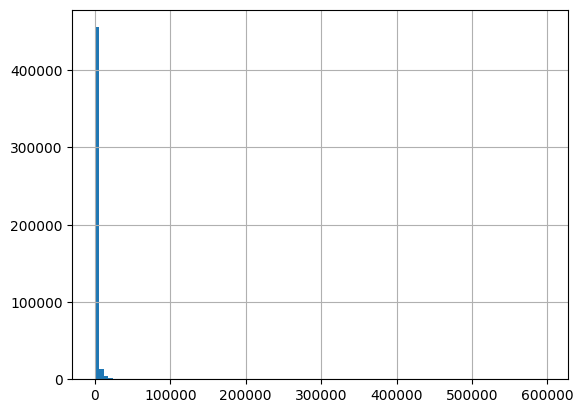

In [3]:
data = data_en.assign(
    first_prompt=lambda df_: df_.conversation.apply(lambda x: x[0]['content']),
    first_prompt_len=lambda df_: df_.first_prompt.str.len()
)

data.first_prompt_len.hist(bins=100)
data.first_prompt_len.describe()

In [4]:
# Let's remove duplicates
print('Before deduplicatoin:', data.shape[0])
data = data.drop_duplicates(subset=['first_prompt'])
print('After deduplication:', data.shape[0])

Before deduplicatoin: 478498
After deduplication: 396678


In [5]:
len_cutoff = data.first_prompt_len.quantile(0.9)
print(len_cutoff)

3904.0


In [6]:
# Let's ignore very long queries
len_cutoff = 140 # use Twitter length :)
data = data.query(f'first_prompt_len <= {len_cutoff}')

In [7]:
data.shape

(136011, 16)

## Let's classify them as Bing queries from COSIT

In [8]:
%%capture 

from setfit import SetFitModel

from tqdm import tqdm
tqdm.pandas()

In [9]:
%%capture
spatial_classifier = SetFitModel.from_pretrained('ilyankou/spatial-classifier')

In [10]:
%%time

# takes ca 2min 15s for 150k samples
preds = spatial_classifier.predict( data.first_prompt.tolist() )

CPU times: user 37.9 s, sys: 8.06 s, total: 45.9 s
Wall time: 2min 13s


In [11]:
data['is_spatial'] = preds

In [12]:
data.is_spatial.value_counts()

is_spatial
0    132445
1      3566
Name: count, dtype: int64

In [13]:
data.to_parquet('interim/wildchat.en.len140.parquet')